# 1.0 - LOAD PACKAGES

## 1.1 - LOAD PACKAGES AND GET DATA

In [1]:
# 0.1 - DATA PREP AND MATH LIBRARIES
import pandas       as pd
import numpy        as np
import re

# PLOTTING
import seaborn      as sns
from   matplotlib                 import pyplot as plt
#%matplotlib inline 


# DECISION TREES
from   sklearn.feature_extraction import DictVectorizer        # CONVERT DATAFRAME TO MATRIX AND APPLY ONE-HOT ENCODING
from   sklearn.model_selection    import train_test_split      # SPLIT THE DATASET
from   sklearn.metrics            import (
                                    roc_auc_score,              # CLASSIFICATION ACCURACY METRIC
                                    mean_squared_error         # REGRESSION ACCURACY METRIC
                                )
from   sklearn.tree               import (
                                    DecisionTreeClassifier,     # CLASSIFICATION PREDICTIONS 
                                    DecisionTreeRegressor,      # REGRESSION PREDICTIONS
                                    export_text                # 
                                )
from   sklearn.ensemble           import RandomForestRegressor # ENEMBLE LEANING


# 2.0 - HELPER FUNCTIONS

In [2]:
# CLEAN STRINGS 
def fn_clean_text(value):
    if not isinstance(value, str):
        return value

    value = value.lower()
    value = value.replace('%', '_pct_')
    value = re.sub(r'[\s()/\-]+', '_', value)  # spaces, slashes, parentheses, hyphens
    value = re.sub(r"""['"]""", '', value)     # remove quotes
    value = re.sub(r'[,;?]', '', value)       # remove punctuation
    return value
    
# CREATE A TABLE SHOWING HOW MANY ROWS ARE MISSING PER COLUMN
def fn_view_col_value_status_table(data):
    if isinstance(data, pd.Series):
        data = data.to_frame()
    elif not isinstance(data, pd.DataFrame):
        raise TypeError("Pass a pandas Series or DataFrame")
        
    print("=" * 80)
    print("VALUES\t\tMISSING\t\t%_MISSING\tCOLUMN")
    print("=" * 80)

    for column_name in data.columns:
        non_missing     = data[column_name].count()
        missing         = data[column_name].isna().sum()
        total           = non_missing + missing
        percent_missing = (missing / total * 100) if total else 0

        print(
            f"{non_missing}\t\t"
            f"{missing}\t\t"
            f"{percent_missing:.2f} %\t\t"
            f"{column_name}"
        )
    print("=" * 80)

# CREATE A TABLE SHOWING A COUNT OF HOW FREQUENTLY THE VALUES IN A FEATURE APPEAR
def fn_view_column_value_counts_old(data):
    if isinstance(data, pd.Series):
        columns = [(data.name or "value", data)]
    elif isinstance(data, pd.DataFrame):
        columns = [(name, data[name]) for name in data.columns]
    else:
        raise TypeError("Pass a pandas Series or DataFrame")

    for column_name, series in columns:
        counts = series.value_counts(dropna=False)
        total = len(series)

        print("=" * 80)
        print(f"\n\'{column_name}\'")
        print("-" * 80)
        print("COUNT\t\tFREQUENCY\t\tVALUE")
        print("=" * 80)

        for value, count in counts.items():
            percent = (count / total * 100) if total else 0
            print(f"{count}\t\t{percent:.2f}%\t\t{value}")

def fn_view_column_value_counts(data):
    if isinstance(data, str):
        data = df[data]  # look up the named column
    elif isinstance(data, pd.DataFrame):
        for column_name in data.columns:
            fn_view_column_value_counts(data[column_name])
        return
    elif not isinstance(data, pd.Series):
        raise TypeError("Pass a column name, pandas Series, or pandas DataFrame")

    column_name = data.name or "value"
    counts = data.value_counts(dropna=False)
    total = len(data)

    print(f"\n{column_name}")
    print("COUNT\t\tFREQUENCY\tVALUE")
    print("=" * 60)

    for value, count in counts.items():
        percent = count / total * 100 if total else 0
        print(f"{count}\t\t{percent:.2f}%\t\t{value}")



# REVIEW FEATURE DATA QUALITY
def fn_view_feature_data_quality(feature_or_dataframe):
    if isinstance(feature_or_dataframe, str):
        data = df[feature_or_dataframe]
    else:
        data = feature_or_dataframe

    fn_view_col_value_status_table(data)
    fn_view_column_value_counts(data)


# 3.0 - BEGIN PREPARING DATA

## 3.1 - GET AND PREVIEW DATA

In [3]:
###########################################################################################
#   3.1.1 - GET DATA
###########################################################################################
data_path  = "C:/Users/duffl/anaconda3/_CT161_GitHub_Repos/ml-zoomcamp-homework/07_midterm_project_plants/data/Australian_plant_translocation_database_PUBLIC_2018(ALL_TRANSLOCATIONS).csv"
df         = pd.read_csv(data_path)

###########################################################################################
#   3.1.2 - CLEAN COLUMN NAMES AND RECORD VALUES
###########################################################################################
df.columns             = [fn_clean_text(column) for column in df.columns]
df                     = df.map(fn_clean_text)

# MANUALLY FIX COLUMN WITH PERIOD IN COLUMN NAME
df['habitat_condition'] = df['habitat_condition_e.g._highly_disturbed_small_remnant_large_remnant_']
df.drop(columns=['habitat_condition_e.g._highly_disturbed_small_remnant_large_remnant_'], inplace=True)

###########################################################################################
#   3.1.3 - PREVIEW NEW COLUMN NAMES 
###########################################################################################
fn_view_col_value_status_table(df)

###########################################################################################
#   3.1.4 - PREVIEW DATA VALUES 
###########################################################################################
df.head(20)

VALUES		MISSING		%_MISSING	COLUMN
1182		0		0.00 %		status_summary
1182		0		0.00 %		translocation_number
1182		0		0.00 %		treatment_number
321		861		72.84 %		treatment_description
1182		0		0.00 %		species
1182		0		0.00 %		family
1182		0		0.00 %		lifeform
1182		0		0.00 %		state
1166		16		1.35 %		conservation_status_epbc_
1156		26		2.20 %		conservation_status_state_
1182		0		0.00 %		latitude_decimal_degrees_
1182		0		0.00 %		longitude_decimal_degrees_
1182		0		0.00 %		bioregion
1182		0		0.00 %		broad_habitat_group
1166		16		1.35 %		habitat_description
871		311		26.31 %		research_to_support_translocation_
1177		5		0.42 %		mitigation_translocation
1182		0		0.00 %		translocation_type
775		407		34.43 %		start_month
1138		44		3.72 %		start_year
892		290		24.53 %		number_of_subsequent_plantings
91		1091		92.30 %		number_of_seeds_direct_seeding_only_
1054		128		10.83 %		number_of_individuals_planted_or_germinated_if_direct_seeding_total_
67		1115		94.33 %		number_planted_notes
1115		67		5.67 %		

,status_summary,translocation_number,treatment_number,treatment_description,species,family,lifeform,state,conservation_status_epbc_,conservation_status_state_,...,medium_term_success_population_persisting_at_secure_site_,long_term_success_self_sustaining_population_established_with_dynamics_comparable_to_natural_populations_,reasons_for_failure_or_sub_optimal_performance_or_success_if_known_,failure_factors_summary,success_factors_summary,notes,project_managed_by,contact_person_s,references,habitat_condition
0,incomplete_but_sufficient_for_analysis,10,1.0,NaN,abutilon_julianae,malvaceae,shrub,norfolk_island,cr,NaN,...,yes,yes,NaN,NaN,NaN,successful_part_of_restoration_planting_and_sp...,NaN,NaN,de_lange_p.j._&_b.g.murray_2003_._chromosome_n...,in_national_park_part_of_restoration_planting
1,incomplete_but_sufficient_for_analysis,11,1.0,NaN,abutilon_julianae,malvaceae,shrub,norfolk_island,cr,NaN,...,yes,yes,NaN,NaN,NaN,successful_part_of_restoration_planting_and_sp...,NaN,NaN,de_lange_p.j._&_b.g.murray_2003_._chromosome_n...,in_national_park_part_of_restoration_planting
2,finalised,854,1.0,propagule_type_seedlings_,acacia_aprica,fabaceae,shrub,wa,en,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_dbca_district,leonie_monks,monks_l_and_coates_d_2002_the_translocation_of...,highly_disturbed_rehabilitated_gravel_pit_in_r...
3,finalised,854,2.0,propagule_type_seeds_,acacia_aprica,fabaceae,shrub,wa,en,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_dbca_district,leonie_monks,monks_l_and_coates_d_2002_the_translocation_of...,highly_disturbed_rehabilitated_gravel_pit_in_r...
4,finalised,855,1.0,NaN,acacia_aprica,fabaceae,shrub,wa,en,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_district,leonie_monks_rebecca_dillon,monks_l_and_coates_d_2002_the_translocation_of...,disturbed_old_farmland_amongst_tree_plantings_
5,finalised,262,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,yes,yes,implementation_of_fire_management_plan_will_en...,NaN,planting_technique_active_disturbance_manageme...,brownlie_et_al_2009_paper:_the_maintenance_of_...,NaN,heather_brownlie_peter_duforq_alison_shapcott,usc_inquiry_into_environmental_offsets_brownli...,highly_disturbed_translocated_community_remnant_
6,incomplete_but_sufficient_for_analysis,263,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,no_,no,planted_out_tube_stock_died_for_various_reason...,climate_dry__site_selection_lack_of_maintenance_,NaN,the_selected_site_was_not_ideal_but_was_the_on...,fraser_coast_regional_council,tina_raveneau,NaN,small_remnant
7,finalised,264,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,no,no,flooding_,climate_flooding__too_few_plants_to_bein_with,NaN,reason_for_translocation:_these_works_were_und...,department_of_transport_and_main_roads_opus_ve...,caroline_haskard_,haskard_c_2014_translocation_compliance_report...,disturbed_small_remnant
8,finalised,265,1.0,NaN,acacia_attenuata,fabaceae,shrub,qld,vu,vu,...,no,no,inappropriate_translocation_habitat,poor_site_selection_lack_of_maintenance,NaN,sippy_creek_revegetation_site_ex_situ_populati...,NaN,robert_lamont,brownlie_h._playford_j._wallace_h._shapcott_a....,NaN
9,finalised,856,1.0,NaN,acacia_awestoniana,fabaceae,shrub,wa,vu,cr,...,NaN,NaN,NaN,NaN,NaN,NaN,dbca_science_and_dbca_district,leonie_monks_rebecca_dillon,NaN,national_park


## 3.2 - DROP RECORDS MARKED AS UNSUITABLE FOR ANALYSIS

In [4]:
###########################################################################################
#   3.2.1 - DROP RECORDS DATASET CREATORS HAVE MARKED AS UNSUITABLE FOR ANALYSIS
###########################################################################################
exclude_status_summary = r'incomplete|unable_to_monitor|finalised '

df                     = df.loc[
                          ~df['status_summary'].str.contains(
                            exclude_status_summary, 
                            na=False
                          )
                        ].copy()
print('records dropped')


records dropped


## 3.3 - DROP FEATURES UNSUITABLE FOR ANALYSIS

In [5]:
###########################################################################################
#   3.3.1 - DROP FEATURES WHOSE 
#           - CONTENT IS UNIQUE ACROSS ALL RECORDS 
#           - FEW RECORDS HAVE VALUES
#           - TOO MANY CATEGORY VALUES SO VERY FEW RECORDS HAVE THE SAME VALUES 
###########################################################################################
exclude_features_list  =    [
                                'status_summary',
                                'treatment_number',
                                'treatment_description', 
                                'species', 
                                'family',
                                'bioregion',
                                'conservation_status_state_',
                                'latitude_decimal_degrees_',
                                'longitude_decimal_degrees_',
                                'habitat_description',
                                'start_month',
                                'start_year',
                                'number_of_seeds_direct_seeding_only_',
                                'number_of_individuals_planted_or_germinated_if_direct_seeding_total_',
                                'number_planted_notes',
                                'watering_in_only', 
                                'watering_<6_months_', 
                                'watering_>6_months_or_in_dry_season_', 
                                'last_monitoring_date',
                                'number_of_plants_surviving',
                                'number_of_subsequent_plantings',
                                'no_second_generation_plants',
                                'short_term_success__pct__of_plants_which_survived_first_year_', 
                                'medium_term_success_population_persisting_at_secure_site_',
                                'long_term_success_self_sustaining_population_established_with_dynamics_comparable_to_natural_populations_',
                                'reasons_for_failure_or_sub_optimal_performance_or_success_if_known_',
                                'failure_factors_summary',
                                'success_factors_summary',
                                'notes',
                                'project_managed_by',
                                'contact_person_s', 
                                'references',
                                'habitat_condition_eg_highly_disturbed_small_remnant_large_remnant_',
                                'propagule_type_seed_seedling_cutting_tissue_culture_whole_plants_etc_',
                                'habitat_condition',
                                'no._second_generation_plants'
                            ]

###########################################################################################
#   3.3.2 - REPORT ANY FEATURES THAT CAN NOT BE FOUND
###########################################################################################
missing                = [col for col in exclude_features_list if col not in df.columns]
print("Features to remove that were not found:\r\n", missing)
print()

###########################################################################################
#   3.3.3 - DROP FEATURES IN LIST
###########################################################################################
df                     = df.drop(columns=exclude_features_list, errors='ignore')

###########################################################################################
#   3.3.3 - REVIEW REMAININNG FEATURES
###########################################################################################
print("=" * 80)
print("===== REMAINING FEATURES =======================================================")
fn_view_col_value_status_table(df)
print("=" * 80)


Features to remove that were not found:
 ['no_second_generation_plants', 'habitat_condition_eg_highly_disturbed_small_remnant_large_remnant_']

===== REMAINING FEATURES =======================================================
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		translocation_number
841		0		0.00 %		lifeform
841		0		0.00 %		state
830		11		1.31 %		conservation_status_epbc_
841		0		0.00 %		broad_habitat_group
665		176		20.93 %		research_to_support_translocation_
841		0		0.00 %		mitigation_translocation
841		0		0.00 %		translocation_type
692		149		17.72 %		soil_preparation_y_n_
692		149		17.72 %		pre_planting_burn_y_n_
681		160		19.02 %		pre_planting_slashing_or_weeding_y_n_
690		151		17.95 %		pre_site_preparation_all_
684		157		18.67 %		herbivore_exclosure_fence_y_n_
684		157		18.67 %		herbivore_exclosure_cages_y_n_
684		157		18.67 %		tree_guards_y_n_
681		160		19.02 %		grazing_protection_all_
691		150		17.84 %		mulching_y_n_
694		147		17.48 %		watering_all_
686		155		18.43 %	

# 4.0 - DATA CLEANING

## 4.1 - FEATURE: 'treatment_number' ==> 'treatment'

## 4.2 - FEATURE: 'lifeform'

In [6]:
df['lifeform'].head()

2    shrub
3    shrub
4    shrub
5    shrub
7    shrub
Name: lifeform, dtype: object

In [7]:
# PREVIEW RAW DATA VALUES 
source_column          = 'lifeform'
destination_column     = 'lifeform'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
dict_map               = {
                            'shrub': 'shrub',
                            'tree': 'tree',
                            'perennial_forb': 'perennial_forb',
                            'ground_orchid': 'ground_orchid',
                            'perennial_vine': 'perennial_vine',
                            'annual_forb': 'annual_forb',
                            'perennial_grass': 'perennial_grass',
                            'perennial_lily': 'perennial_lily',
                            'annual_grass': 'annual_grass',
                            'cycad': 'cycad',
                            'perennial_forb_fern_': 'perennial_forb_fern',
                            'perennial_sedge': 'perennial_sedge',
                            'perennnial_forb': 'perennnial_forb',
                            'perennial_sedge': 'perennial_sedge',
                            'perennnial_forb': 'perennnial_forb',
                            'orchid_epiphytic_': 'orchid_epiphytic',
                            'palm': 'palm',
                            'grass_tree': 'grass_tree',
                            'tree_mallee_': 'tree_mallee',
                            'fern': 'fern',
                            'epiphyte': 'epiphyte',
                            'annual_sedge': 'annual_sedge',
                            'tree_': 'tree',
                            'perennial_aquatic_forb': 'perennial_aquatic_forb',
                            'shrub_' : 'shrub'
                         }
df[destination_column]     = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

if (source_column != destination_column): 
    df.drop(columns=['lifeform'], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		lifeform

lifeform
COUNT		FREQUENCY	VALUE
394		46.85%		shrub
141		16.77%		tree
95		11.30%		perennial_forb
69		8.20%		ground_orchid
35		4.16%		perennial_vine
26		3.09%		annual_forb
22		2.62%		annual_grass
20		2.38%		perennial_grass
8		0.95%		cycad
7		0.83%		perennial_lily
5		0.59%		perennial_forb_fern_
5		0.59%		perennnial_forb
2		0.24%		orchid_epiphytic_
2		0.24%		grass_tree
2		0.24%		tree_mallee_
2		0.24%		fern
2		0.24%		epiphyte
1		0.12%		annual_sedge
1		0.12%		palm
1		0.12%		perennial_aquatic_forb
1		0.12%		shrub_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		lifeform

lifeform
COUNT		FREQUENCY	VALUE
395		46.97%		shrub
141		16.77%		tree
95		11.30%		perennial_forb
69		8.20%		ground_orchid
35		4.16%		perennial_vine
26		3.09%		annual_forb
22		2.62%		annual_grass
20		2.38%		perennial_grass
8		0.95%		cycad
7		0.83%		perennial_lily
5		0.59%		perennial_forb_fern
5		0.59%		perennnial_forb
2		0.24%		grass_tree
2		0.24%		orchid_epiphytic
2

## 4.3 - FEATURE: 'state'

In [8]:
# PREVIEW RAW DATA VALUES 
source_column           = 'state' 
destination_column      = 'state' 

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
# df[destination_column]  = df[source_column].copy()
df[destination_column]= df[source_column].str.strip().replace('qld_', 'qld')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=['lifeform'], inplace=True)
    
# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		state

state
COUNT		FREQUENCY	VALUE
207		24.61%		nsw
196		23.31%		vic
186		22.12%		sa
133		15.81%		wa
91		10.82%		qld
20		2.38%		tas
6		0.71%		act
2		0.24%		qld_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		state

state
COUNT		FREQUENCY	VALUE
207		24.61%		nsw
196		23.31%		vic
186		22.12%		sa
133		15.81%		wa
93		11.06%		qld
20		2.38%		tas
6		0.71%		act


## 4.4 - FEATURE: 'conservation_status_epbc_'

In [9]:
# PREVIEW RAW DATA VALUES 
source_column           = 'conservation_status_epbc_' 
destination_column      = 'conservation_status' 

fn_view_feature_data_quality(source_column)

# CLEAN DATA                 
dict_map               = {
                            'en' : 'endangered',
                            'vu' : 'vulnerable',
                            'cr' : 'critically_endangered',
                            'vu' : 'vulnerable',
                            'vu_' : 'vulnerable',
                            'rotap_2rc_' : 'rare',
                            'not_listed_rotap_3rca_' : 'rare',
                            'not_listed_rotap_' : 'not_listed',
                            'ev' : 'extinct_in_wild',
                         }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
830		11		1.31 %		conservation_status_epbc_

conservation_status_epbc_
COUNT		FREQUENCY	VALUE
415		49.35%		en
175		20.81%		not_listed
150		17.84%		vu
66		7.85%		cr
11		1.31%		nan
10		1.19%		vu_
6		0.71%		rotap_2rc_
4		0.48%		not_listed_rotap_3rca_
3		0.36%		not_listed_rotap_
1		0.12%		ev
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		conservation_status

conservation_status
COUNT		FREQUENCY	VALUE
415		49.35%		endangered
178		21.17%		not_listed
160		19.02%		vulnerable
66		7.85%		critically_endangered
11		1.31%		missing
10		1.19%		rare
1		0.12%		extinct_in_wild


## 4.5 - FEATURE: 'broad_habitat_group'

In [10]:
# PREVIEW RAW DATA VALUES 
source_column          = 'broad_habitat_group'
destination_column     = 'habitat'

fn_view_feature_data_quality(source_column)

# CLEAN DATA 
dict_map               = {
                            'rainforest': 'rainforest',
                            'southern_shrublands_heathlands_woodlands': 'southern_shrublands_heathlands_woodlands',
                            'southern_shrublands_heathlands_woodlands_': 'southern_shrublands_heathlands_woodlands',
                            'grassland': 'grassland',
                            'grassy_woodland': 'grassy_woodland',
                            'wetland': 'wetland',
                            'dry_sclerophyll': 'dry_sclerophyll',
                            'mallee': 'mallee',
                            'grassland_with_chenopods': 'grassland_with_chenopods',
                            'coastal_heath': 'coastal_heath',
                            'wet_sclerophyll': 'wet_sclerophyll',
                            'banded_ironstone': 'banded_ironstone',
                            'grassland_sub_tropical_': 'grassland_sub_tropical',
                            'montane': 'montane',
                            'other': 'other',
                            'coastal_shrubland': 'coastal_shrubland',
                            'semi_arid_woodland': 'semi_arid_woodland',
                            'wetland_floodplain_': 'wetland_floodplain',
                            'coastal_headland': 'coastal_headland',
                            'coastal_forest': 'coastal_forest',
                            'coastal_dunes': 'coastal_dunes',
                            'grassland_': 'grassland',
                            'grassland_lomandra_': 'grassland_lomandra',
                            'wetland_riparian_': 'wetland_riparian',
                       }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('unk')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		broad_habitat_group

broad_habitat_group
COUNT		FREQUENCY	VALUE
164		19.50%		rainforest
135		16.05%		southern_shrublands_heathlands_woodlands
95		11.30%		southern_shrublands_heathlands_woodlands_
82		9.75%		grassland
47		5.59%		mallee
47		5.59%		grassy_woodland
42		4.99%		grassland_with_chenopods
38		4.52%		wetland
36		4.28%		coastal_heath
21		2.50%		dry_sclerophyll
21		2.50%		wet_sclerophyll
20		2.38%		grassland_sub_tropical_
18		2.14%		montane
16		1.90%		coastal_shrubland
11		1.31%		semi_arid_woodland
9		1.07%		other
8		0.95%		banded_ironstone
7		0.83%		coastal_forest
6		0.71%		wetland_floodplain_
6		0.71%		dry_rainforest
5		0.59%		coastal_dunes
2		0.24%		grassland_lomandra_
2		0.24%		wetland_riparian_
2		0.24%		grassland_
1		0.12%		coastal_headland
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		habitat

habitat
COUNT		FREQUENCY	VALUE
230		27.35%		southern_shrublands_heathlands_woodlands
164		19.50%		rainforest
84		9.99%		grassland

## 4.6 - FEATURE: 'research_to_support_translocation_'

In [11]:
# PREVIEW RAW DATA VALUES 
source_column          = 'research_to_support_translocation_'
destination_column     = 'research'

fn_view_feature_data_quality(source_column)

# CLEAN DATA 
is_empty               = df[source_column].isna() | df[source_column].astype('string').str.strip().eq('')
is_underscore          = df[source_column].astype('string').str.strip().eq('_')

df[destination_column] = 'yes'
df.loc[is_empty | is_underscore, destination_column] = 'no'

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
665		176		20.93 %		research_to_support_translocation_

research_to_support_translocation_
COUNT		FREQUENCY	VALUE
197		23.42%		yes
176		20.93%		nan
78		9.27%		no
54		6.42%		low
45		5.35%		medium
28		3.33%		previous_translocation
27		3.21%		genetics_pollinator_studies
23		2.73%		genetics
18		2.14%		yes_experimental_planting_trials_+_genetics_+_field_based_cross_pollination_experiment_
18		2.14%		yes_genetics_
16		1.90%		yes_genetics_review_of_translocations_undertaken_to_date_long_term_monitoring_
15		1.78%		this_was_a_pasture_mgmt_experimental_translocation
13		1.55%		fertilizer_trial
11		1.31%		y
11		1.31%		experimental_translocation
8		0.95%		yes_
7		0.83%		genetics_translocation_experiment
6		0.71%		yes_propagation_field_trials_
6		0.71%		yes_preliminary_translocation_trials_to_understand_microsite_and_habitat_preferences_
6		0.71%		yes_genetics_pollination_
5		0.59%		high
4		0.48%		experimental_translocations_previously_undertaken._
4		0.48%		yes_ph

## 4.7 - FEATURE: 'mitigation_translocation'

In [12]:
# PREVIEW RAW DATA VALUES 
source_column          = 'mitigation_translocation'
destination_column     = 'mitigation'

# fn_feature_data_quality(source_column)

# CLEAN DATA 
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'unk'
                          }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		mitigation

mitigation
COUNT		FREQUENCY	VALUE
565		67.18%		no
276		32.82%		yes


## 4.9 - FEATURE: 'translocation_type'

In [13]:
# PREVIEW RAW DATA VALUES 
source_column          = 'translocation_type'
destination_column     = 'translocation'

fn_view_feature_data_quality(source_column)

# CLEAN DATA 
dict_map               = {
                            'introduction'               : 'introduction',
                            'augmentation'               : 'augmentation',
                            'augmentation_experimental_' : 'augmentation',
                            'introduction_'              : 'introduction',
                            'introduction_salvage_'      : 'introduction',
                            'introduction_experimental_' : 'introduction',
                            'introduction_seed_orchard_' : 'introduction',
                            'augmentation_salvage_'      : 'augmentation',
                            'restocking_of_original_introduction_above_' : 'reintroduction',
                            'reintroduction'             : 'reintroduction',
                            'introduction_reintroduction_to_riverland_' : 'introduction_reintroduction',
                            'restocking_of_above_'       : 'reintroduction',
                            'assisted_migration'         : 'introduction',
                            'introduction_augmentation_' : 'introduction_augmentation_',
                            'introduction_different_site_but_same_remnant_as_natural_population_' : 'introduction',
                          }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		translocation_type

translocation_type
COUNT		FREQUENCY	VALUE
595		70.75%		introduction
117		13.91%		augmentation
30		3.57%		augmentation_experimental_
24		2.85%		introduction_
20		2.38%		introduction_salvage_
16		1.90%		introduction_experimental_
11		1.31%		introduction_seed_orchard_
7		0.83%		augmentation_salvage_
7		0.83%		restocking_of_original_introduction_above_
5		0.59%		reintroduction
2		0.24%		introduction_reintroduction_to_riverland_
2		0.24%		restocking_of_above_
2		0.24%		assisted_migration
2		0.24%		introduction_augmentation_
1		0.12%		introduction_different_site_but_same_remnant_as_natural_population_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		translocation

translocation
COUNT		FREQUENCY	VALUE
669		79.55%		introduction
154		18.31%		augmentation
14		1.66%		reintroduction
2		0.24%		introduction_reintroduction
2		0.24%		introduction_augmentation_


## 4.11 - FEATURE: 'soil_preparation_y_n_'

In [14]:
# PREVIEW RAW DATA VALUES 
source_column           = 'soil_preparation_y_n_'
destination_column      = 'soil_prep'

# fn_view_feature_data_quality(source_column)

# CLEAN DATA 
df[destination_column]  = df[source_column].astype('string').str[0]
dict_map                = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'unk'
                          }
df[destination_column]  = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		soil_prep

soil_prep
COUNT		FREQUENCY	VALUE
464		55.17%		no
228		27.11%		yes
149		17.72%		missing


## 4.12 - FEATURE: 'pre_planting_burn_y_n_'

In [15]:
# PREVIEW RAW DATA VALUES 
source_column          = 'pre_planting_burn_y_n_'
destination_column     = 'pre_planting_burn'

# fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map                = {
                            'n' : 'no',
                            'y' : 'yes', 
                            'u' : 'unk'
                          }
df[destination_column]  = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		pre_planting_burn

pre_planting_burn
COUNT		FREQUENCY	VALUE
667		79.31%		no
149		17.72%		missing
25		2.97%		yes


## 4.13 - FEATURE: 'pre_planting_slashing_or_weeding_y_n_'

In [16]:
# PREVIEW RAW DATA VALUES 
source_column          = 'pre_planting_slashing_or_weeding_y_n_'
destination_column     = 'pre_planting_slashing_or_weeding'

# fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'unk'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		pre_planting_slashing_or_weeding

pre_planting_slashing_or_weeding
COUNT		FREQUENCY	VALUE
402		47.80%		no
278		33.06%		yes
161		19.14%		missing


## 4.14 - FEATURE: 'pre_site_preparation_all_'

In [17]:
# PREVIEW RAW DATA VALUES 
source_column          = 'pre_site_preparation_all_'
destination_column     = 'pre_site_prep'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
dict_map               = {
                            '0.0' : 'no',
                            '1.0' : 'yes',
                            'u' : 'unk'
                          }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
690		151		17.95 %		pre_site_preparation_all_

pre_site_preparation_all_
COUNT		FREQUENCY	VALUE
363		43.16%		1.0
327		38.88%		0.0
151		17.95%		nan
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		pre_site_prep

pre_site_prep
COUNT		FREQUENCY	VALUE
363		43.16%		yes
327		38.88%		no
151		17.95%		missing


## 4.15 - FEATURE: 'herbivore_exclosure_fence_y_n_'

In [18]:
# PREVIEW RAW DATA VALUES 
source_column          = 'herbivore_exclosure_fence_y_n_'
destination_column     = 'exclosure_fence'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'p' : 'yes'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA  
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
684		157		18.67 %		herbivore_exclosure_fence_y_n_

herbivore_exclosure_fence_y_n_
COUNT		FREQUENCY	VALUE
424		50.42%		n
180		21.40%		y
157		18.67%		nan
24		2.85%		y_grazing_removed_from_property_
8		0.95%		y_sheep_and_cattle_excluded_hares_present_
6		0.71%		y_stock_and_rabbit_proof_
5		0.59%		y_stock_
4		0.48%		y_half_of_plots_
4		0.48%		y_rabbits_and_stock_excluded_
4		0.48%		
3		0.36%		pre_planting_rabbit_warren_fumigation
2		0.24%		y_different_treatments_
2		0.24%		y_rabbit_and_kangaroo
2		0.24%		y_some
2		0.24%		n_
1		0.12%		n_stock_fence_only_plants_not_really_grazed_
1		0.12%		y_domestic_stock_excluded_
1		0.12%		y_total_exclosure_
1		0.12%		y_roo_fenced_
1		0.12%		y_stock_+_rabbits_excluded_
1		0.12%		n_not_required_as_no_browsers_on_island_
1		0.12%		y_wallabies_and_hares_
1		0.12%		y_macropods_excluded_
1		0.12%		y_wallaby_exclosure_
1		0.12%		y_except_ducks!_
1		0.12%		y_stock_only_+_rabbit_and_hare_control_initially
1		0.12%		y_
1		0.12%		y

## 4.16 - FEATURE: 'herbivore_exclosure_cages_y_n_'

In [19]:
# PREVIEW RAW DATA VALUES 
source_column          = 'herbivore_exclosure_cages_y_n_'
destination_column     = 'exclosure_cage'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'unk',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('unk') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
684		157		18.67 %		herbivore_exclosure_cages_y_n_

herbivore_exclosure_cages_y_n_
COUNT		FREQUENCY	VALUE
507		60.29%		n
157		18.67%		nan
139		16.53%		y
20		2.38%		y_
4		0.48%		
4		0.48%		y_only_for_plants_surviving_after_year_6_
3		0.36%		y_plastic_mesh_guards_
3		0.36%		y_portion_caged_
2		0.24%		y_rabbits_
1		0.12%		y_possums_and_wallabies_
1		0.12%		y_some_plants_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		exclosure_cage

exclosure_cage
COUNT		FREQUENCY	VALUE
507		60.29%		no
173		20.57%		yes
161		19.14%		unk


## 4.17 - FEATURE: 'tree_guards_y_n_'

In [20]:
# PREVIEW RAW DATA VALUES 
source_column          = 'tree_guards_y_n_'
destination_column     = 'tree_guard'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                            'u' : 'unk',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)


VALUES		MISSING		%_MISSING	COLUMN
684		157		18.67 %		tree_guards_y_n_

tree_guards_y_n_
COUNT		FREQUENCY	VALUE
629		74.79%		n
157		18.67%		nan
49		5.83%		y
1		0.12%		y_for_first_year_
1		0.12%		y_
1		0.12%		y_staked_for_stability
1		0.12%		y_hessian_barriers_for_shade
1		0.12%		y_hessian_barriers
1		0.12%		y_outside_of_fencing_guards_were_used_to_protect_plants_4_6_survived_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		tree_guard

tree_guard
COUNT		FREQUENCY	VALUE
629		74.79%		no
157		18.67%		missing
55		6.54%		yes


## 4.18 - FEATURE: 'grazing_protection_all_'

In [21]:
# PREVIEW RAW DATA VALUES 
source_column          = 'grazing_protection_all_'
destination_column     = 'grazing_protection'

# fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            '0' : 'no',
                            '1' : 'yes',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		grazing_protection

grazing_protection
COUNT		FREQUENCY	VALUE
427		50.77%		yes
254		30.20%		no
160		19.02%		missing


## 4.19 - FEATURE: 'mulching_y_n_'

In [22]:
# PREVIEW RAW DATA VALUES 
source_column          = 'mulching_y_n_'
destination_column     = 'mulch'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'n' : 'no',
                            'y' : 'yes',
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing') 

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
691		150		17.84 %		mulching_y_n_

mulching_y_n_
COUNT		FREQUENCY	VALUE
642		76.34%		n
150		17.84%		nan
46		5.47%		y
2		0.24%		y_cane_mulch
1		0.12%		y_matting_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		mulch

mulch
COUNT		FREQUENCY	VALUE
642		76.34%		no
150		17.84%		missing
49		5.83%		yes


## 4.20 - FEATURE: 'watering_all_'

In [23]:
# PREVIEW RAW DATA VALUES 
source_column          = 'watering_all_'
destination_column     = 'watering'

# fn_view_feature_data_quality(source_column)

# CLEAN DATA  
dict_map               = {
                            '0.0' : 'no',
                            '1.0' : 'yes',
                            'u'   : 'unk'
                          }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		watering

watering
COUNT		FREQUENCY	VALUE
421		50.06%		yes
273		32.46%		no
147		17.48%		missing


## 4.21 - FEATURE: 'burnt_0_unburnt_1_planned_2_wildfire_'

In [24]:
# PREVIEW RAW DATA VALUES 
source_column          = 'burnt_0_unburnt_1_planned_2_wildfire_'
destination_column     = 'burnt'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
dict_map               = {
                            '0'   : 'unburnt',
                            '1'   : 'planned',
                            '2'   : 'wildfire',
                            '1_2' : 'planned_wildfire',
                         }
df[destination_column] = df[source_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
686		155		18.43 %		burnt_0_unburnt_1_planned_2_wildfire_

burnt_0_unburnt_1_planned_2_wildfire_
COUNT		FREQUENCY	VALUE
608		72.29%		0
155		18.43%		nan
66		7.85%		1
8		0.95%		2
4		0.48%		1_2
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		burnt

burnt
COUNT		FREQUENCY	VALUE
608		72.29%		unburnt
155		18.43%		missing
66		7.85%		planned
8		0.95%		wildfire
4		0.48%		planned_wildfire


## 4.22 - FEATURE: 'weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_'

In [25]:
# PREVIEW RAW DATA VALUES 
source_column          = 'weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_'
destination_column     = 'weeding'

print('#####  RAW  #####')
fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str.strip().str[0]
dict_map               = {
                            'n'   : 'no',
                            'y'   : 'yes',
                            '0'   : 'yes',
                            '1'   : 'yes',
                            '2'   : 'yes',
                            '3'   : 'yes',
                            '4'   : 'yes',
                            '5'   : 'yes',
                            '6'   : 'yes',
                            '7'   : 'yes',
                            '8'   : 'yes',
                            '9'   : 'yes',
                            'a'   : 'yes',
                            'c'   : 'yes',
                            'o'   : 'yes',
                            'r'   : 'yes',
                            't'   : 'yes',
                            'w'   : 'yes',
                            'u'   : 'unk'
                         }
df[destination_column] = df[destination_column].astype('string').replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
print('##### CLEANED #####')
fn_view_feature_data_quality(destination_column)

#####  RAW  #####
VALUES		MISSING		%_MISSING	COLUMN
676		165		19.62 %		weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_

weeding_includes_exotic_and_native_competitors_number_of_times_or_y_n_
COUNT		FREQUENCY	VALUE
281		33.41%		n
165		19.62%		nan
122		14.51%		y
36		4.28%		4_years
31		3.69%		not_detailed
17		2.02%		3+
15		1.78%		y_slashed_
13		1.55%		not_documented
13		1.55%		3
11		1.31%		0.00
10		1.19%		y_periodically_by_hand_
10		1.19%		y:_2_3_yr_within_cages
9		1.07%		
8		0.95%		regular
7		0.83%		2
6		0.71%		3x_year
5		0.59%		1
5		0.59%		y_twice_
4		0.48%		y_regular_
4		0.48%		annually
3		0.36%		18.00
3		0.36%		12.00
2		0.24%		y_occasional_
2		0.24%		ongoing
2		0.24%		3.00
2		0.24%		c.2x_year_with_concerted_effort_following_burning_
2		0.24%		y_spring_1987_capeweed_only_targeted_
2		0.24%		y_spraying_+_hand_weeding_2yrs_
2		0.24%		12_weeks
2		0.24%		c.15_quarterly_with_extra_attention_post_burn_
2		0.24%		y:_2_3_yr_within_imm._vicinity_of_plants
2		0.24%		y_6yrs

## 4.23 - FEATURE: 'plants_surviving__pct__'

In [26]:
source_column          = 'plants_surviving__pct__'
destination_column_pct = 'plants_surviving_pct'
destination_column_cnt = 'plants_surviving_cnt'

fn_view_feature_data_quality(source_column)

##########################################################################################
# NORMALIZE PERCENTAGE OF PLANTS THAT SURVIVED TRANSPLANTING
###########################################################################################
source = df[source_column].astype('string').str.strip()

replacements = {
    '<NA>'                          : '0.00',
    '<na>'                          : '0.00',
    '??'                            : '0.00',
    '#div/0!'                       : '0.00',
    '#ref!'                         : '0.00',
    '#value!'                       : '0.00',
    'apr_00'                        : '0.00',
    'n_a_annual_'                   : '0.00',
    'n_a_for_annual_species'        : '0.00',
    'n_a_annual_plant_'             : '0.00',
    'n_a_direct_seeding_'           : '0.00',
    'n_a_short_lived_'              : '0.00',
    'Not monitored yet'             : '0.00',
    'unknown_probably_0_'           : '0.00',
    '0_but_substantial_recruitment_': '0.00',
    '<5'                            : '5.00',
    '<10'                           : '10.00',
    '>10'                           : '10.00',
    '>10_pct_'                      : '10.00',
    '16_pct_'                       : '16.00',
    '4_pct_'                        : '4.00', 
    '11_pct_'                       : '11.00',
    'c20'                           : '20.00',
    'c25_pct_'                      : '25.00',
    '17_pct_'                       : '17.00',
    '<20'                           : '20.00',
    'c.20'                          : '20.00',
    '>25'                           : '25.00',
    '>25_pct_'                      : '25.00',
    'c.25'                          : '25.00',
    '20-40_pct_'                    : '30.00',
    '20-40'                         : '30.00',
    'c.25'                          : '25.00',
    '29_pct_'                       : '29.00',
    '~30'                           : '30.00',
    '>30'                           : '30.00',
    '>33'                           : '33.00',
    '~40'                           : '40.00',
    '>40'                           : '40.00',
    '<50?'                          : '50.00',
    '<50_pct_'                      : '50.00',
    '<50_pct_?'                     : '50.00',
    '<50?'                          : '50.00',
    '50_pct_'                       : '50.00',
    '~50'                           : '50.00',
    '>50_pct_'                      : '50.00',
    '>50'                           : '50.00',
    '>50_pct_'                      : '50.00',
    '52_pct_'                       : '52.00',
    '60_pct_'                       : '60.00',
    '69_pct_'                       : '69.00',
    'unknown_but_probably_>75_pct_' : '75.00',
    '77_pct_'                       : '77.00',
    '80_pct_'                       : '80.0',
    '80_pct__across_all_sites_and_treatments_'  : '80.00',
    '80_pct_ (across all sites and treatments)' : '80.00',
    '83_pct_'                       : '83.00',
    '85_pct_'                       : '85.0',
    '>90'                           : '90.00',
    '>95'                           : '95.00',
    '>95_pct_'                      : '95.00',
    '100_pct_'                      : '100.00',
    '>100_with_recruitment_'        : '0.00',
    'good'                          : '0.00',
    'unknown'                       : '0.00',
    'Unknown'                       : '0.00',
    'unknown_number_germinating_not_documented_' : '0.00',
    'unknown_how_many_were_planted_in_total'     : '0.00',
    'unknown_number_of_germinants_not_counted_'  : '0.00',
    'too_early'                     : '0.00',
    'plants_in_the_ground_for_<_12_months'       : '0.00',
    '<12_months_since_planting'     : '0.00',
    '<_12_mnths_since_translocation': '0.00',
    '<12_months_elapsed'            : '0.00',
    '_pct_'                         : '0.00',
}

cleaned = (
    source.replace(replacements)
          .str.replace('%', '', regex=False)
          .str.strip()
)

parts = cleaned.str.split(':',n=1)

# CREATE NEW COLUMN
df[destination_column_cnt] = (
    pd.to_numeric(parts.str[0], errors='coerce')
      .fillna(0.0)
)

df[destination_column_pct] = (
    pd.to_numeric(parts.str[1], errors='coerce')
      .fillna(0.0)
)
# df 'col_plants_surviving_pct'] = parts.str[0].astype('string').str.strip()
# df['col_plants_surviving_ct'] = parts.str[1].astype('string').str.strip()

# DROP ORIGINAL COLUMN 
df.drop(columns=[source_column], inplace=True)

fn_view_column_value_counts(destination_column_pct)
fn_view_column_value_counts(destination_column_cnt)

# df[['plants_surviving__pct__','col_plants_surviving_cnt','col_plants_surviving_pct']].head(30)


VALUES		MISSING		%_MISSING	COLUMN
676		165		19.62 %		plants_surviving__pct__

plants_surviving__pct__
COUNT		FREQUENCY	VALUE
165		19.62%		nan
126		14.98%		0.00
79		9.39%		100.00
15		1.78%		<12_months_elapsed
13		1.55%		50.00
13		1.55%		too_early
12		1.43%		n_a_short_lived_
11		1.31%		unknown_number_of_germinants_not_counted_
9		1.07%		25.00
9		1.07%		80.00
8		0.95%		75.00
7		0.83%		
6		0.71%		4.00
6		0.71%		60.00
6		0.71%		40.00
6		0.71%		42.00
6		0.71%		31.00
5		0.59%		38.00
5		0.59%		0
5		0.59%		10.00
5		0.59%		20.00
5		0.59%		78.00
4		0.48%		88.00
4		0.48%		18.00
4		0.48%		#ref!
4		0.48%		90.00
4		0.48%		n_a_annual_plant_
4		0.48%		unknown
4		0.48%		n_a_for_annual_species
4		0.48%		59.00
4		0.48%		33.00
4		0.48%		67.00
4		0.48%		>50_pct_
4		0.48%		85_pct_
4		0.48%		n_a_annual_
4		0.48%		50
4		0.48%		45.00
3		0.36%		6.70
3		0.36%		48.00
3		0.36%		2.00
3		0.36%		64.00
3		0.36%		70.00
3		0.36%		86.00
3		0.36%		3.00
3		0.36%		>50
3		0.36%		15.00
3		0.36%		<_12_mnths_since_translocation


## 4.24 - FEATURE: 'reproductive_flowering_fruiting_y_n_'

In [27]:
# PREVIEW RAW DATA VALUES 
source_column          = 'reproductive_flowering_fruiting_y_n_'
destination_column     = 'flowering_fruiting'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0]
dict_map               = {
                            'y'   : 'yes',
                            'n'   : 'no',
                            't'   : 'unk',
                            'p'   : 'unk',
                            '<'   : 'unk',
                            'u'   : 'unk',
                            'unk' : 'unk'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)

VALUES		MISSING		%_MISSING	COLUMN
639		202		24.02 %		reproductive_flowering_fruiting_y_n_

reproductive_flowering_fruiting_y_n_
COUNT		FREQUENCY	VALUE
322		38.29%		y
240		28.54%		n
202		24.02%		nan
16		1.90%		yes
14		1.66%		too_soon
7		0.83%		
7		0.83%		unknown
7		0.83%		<12_months_elapsed
3		0.36%		n_
3		0.36%		<12_months_since_planting
3		0.36%		not_recorded
3		0.36%		y_
2		0.24%		y_flowered_
2		0.24%		y_89_pct__flowered_
2		0.24%		too_early
2		0.24%		no
1		0.12%		plants_in_the_ground_for_<_12_months
1		0.12%		yes_but_<10_pct__
1		0.12%		y_65_pct__flowered_
1		0.12%		not_documented
1		0.12%		y_a_few_flowered_then_withered_
1		0.12%		n_minimal_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		flowering_fruiting

flowering_fruiting
COUNT		FREQUENCY	VALUE
348		41.38%		yes
250		29.73%		no
209		24.85%		missing
34		4.04%		unk


## 4.25 - FEATURE: 'second_generation_y_n_'

In [28]:
# PREVIEW RAW DATA VALUES 
source_column          = 'second_generation_y_n_'
destination_column     = 'second_gen'

fn_view_feature_data_quality(source_column)

# CLEAN DATA  
df[destination_column] = df[source_column].astype('string').str[0:3]
dict_map               = {
                            'y'   : 'yes',
                            'y_'  : 'yes',
                            'yes' : 'yes',
                            'y_4' : 'yes',
                            'y_f' : 'yes',
                            'y_i' : 'yes',
                            'y_r' : 'yes',
                            'y_v' : 'yes',
                            'n'   : 'no', 
                            'n_'  : 'no',  
                            '0'   : 'no', 
                            '0.0' : 'no', 
                            'too' : 'too_soon',
                            'pla' : 'too_soon',
                            '<12' : 'too_soon',
                            ''    : 'missing',
                            'not' : 'missing',
                            'u'   : 'missing',
                            'unk' : 'missing'
                         }
df[destination_column] = df[destination_column].astype('string').str.strip().replace(dict_map).fillna('missing')

# DROP ORIGINAL COLUMN 
if (source_column != destination_column): 
    df.drop(columns=[source_column], inplace=True)

# PREVIEW CLEANED DATA 
fn_view_feature_data_quality(destination_column)



VALUES		MISSING		%_MISSING	COLUMN
682		159		18.91 %		second_generation_y_n_

second_generation_y_n_
COUNT		FREQUENCY	VALUE
434		51.61%		n
159		18.91%		nan
114		13.56%		y
50		5.95%		too_soon
26		3.09%		too_early
20		2.38%		no
14		1.66%		y_vegetative_
3		0.36%		
2		0.24%		y_
2		0.24%		unknown
2		0.24%		<12_months_elapsed
2		0.24%		not_assessed
2		0.24%		0
1		0.12%		plants_in_the_ground_for_<_12_months
1		0.12%		y_runners
1		0.12%		unknown_probably_not_
1		0.12%		not_monitored_in_2015
1		0.12%		yes
1		0.12%		y_4_seedlings_from_seed_in_soil_plug_moved_with_plant_
1		0.12%		not_documented
1		0.12%		y_from_seed_stored_in_soil_moved_with_plants_not_from_translocated_plants_
1		0.12%		y_in_soil_plug_
1		0.12%		0.00
1		0.12%		n_
VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		second_gen

second_gen
COUNT		FREQUENCY	VALUE
458		54.46%		no
169		20.10%		missing
135		16.05%		yes
79		9.39%		too_soon


## 4.26 - ADJUST FOR MULTI-CLASS FEATURES

# 5.0 - EDA

## 5.1 - DISTRIBUTION OF SECOND GENERATION PLANTS

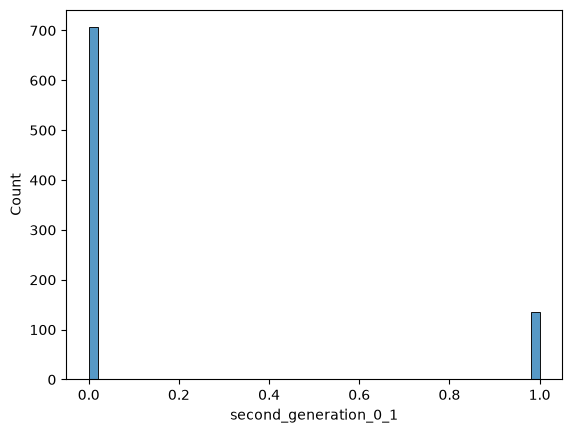

In [29]:
# PLOT 'second_generation_y_n_'

# CONVERT CATEGORICAL INFORMATION TO NUMERIC USING 'second_generation_0_1_'
dict_map = {
    'yes': 1,
    'no' : 0,
    'unk': 0,
}
source = df['second_gen'].astype('string').str.strip().str.lower()

df['second_generation_0_1'] = (
    source.map(dict_map)
          .fillna(0)
          .astype('int32')
)

# PLOT
sns.histplot(df['second_generation_0_1'], bins=50)

# DROP TEMP COLUMN USED TO CREATE THE PLOT
df.drop(columns=['second_generation_0_1'], inplace=True)

# 6.0 - SPLIT DATASET

In [30]:
# REVIEW COLUMNS
fn_view_col_value_status_table(df)

VALUES		MISSING		%_MISSING	COLUMN
841		0		0.00 %		translocation_number
841		0		0.00 %		lifeform
841		0		0.00 %		state
841		0		0.00 %		conservation_status
841		0		0.00 %		habitat
841		0		0.00 %		research
841		0		0.00 %		mitigation
841		0		0.00 %		translocation
841		0		0.00 %		soil_prep
841		0		0.00 %		pre_planting_burn
841		0		0.00 %		pre_planting_slashing_or_weeding
841		0		0.00 %		pre_site_prep
841		0		0.00 %		exclosure_fence
841		0		0.00 %		exclosure_cage
841		0		0.00 %		tree_guard
841		0		0.00 %		grazing_protection
841		0		0.00 %		mulch
841		0		0.00 %		watering
841		0		0.00 %		burnt
841		0		0.00 %		weeding
841		0		0.00 %		plants_surviving_cnt
841		0		0.00 %		plants_surviving_pct
841		0		0.00 %		flowering_fruiting
841		0		0.00 %		second_gen


In [31]:
# SPLIT DATASET
# from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df,            test_size=0.2,  random_state=11)
df_train, df_val       = train_test_split(df_full_train, test_size=0.25, random_state=11)

# RESET INDEX 
df_train               = df_train.reset_index(drop=True)
df_val                 = df_val.reset_index(drop=True)
df_test                = df_test.reset_index(drop=True)

# CREATE TARGET VECTOR
# SET TARGET COLUMN
target_column = "second_gen"

# CREATE TARGET VECTOR
y_train = (df_train[target_column] == 'default').astype('int').values
y_val   = (df_val[target_column]   == 'default').astype('int').values
y_test  = (df_test[target_column]  == 'default').astype('int').values

# DROP TARGET FROM THE FEATURE MATRIX
for df in (df_train, df_val, df_test):
    df.drop(columns=[target_column], inplace=True)

In [32]:
train_dicts            = df_train.fillna(0).to_dict(orient='records')

dv                     = DictVectorizer(sparse=True)
X_train                = dv.fit_transform(train_dicts)

In [33]:
# CONVERT ONE-HOT ENCODED DICTIONARY BACK INTO PANDAS TO HANDLE WITH MULTI-CLASS CLASSIFICATIONS
X_train_df             = pd.DataFrame.sparse.from_spmatrix(
                            X_train,
                            columns=dv.get_feature_names_out()
                         ).sparse.to_dense()
X_train_df.index       = df_train.index



In [36]:
# DEBUG - REVIEW ONE-HOT ENCODED FEATURES 
fn_view_col_value_status_table(X_train_df)

VALUES		MISSING		%_MISSING	COLUMN
504		0		0.00 %		burnt=missing
504		0		0.00 %		burnt=planned
504		0		0.00 %		burnt=planned_wildfire
504		0		0.00 %		burnt=unburnt
504		0		0.00 %		burnt=wildfire
504		0		0.00 %		conservation_status=critically_endangered
504		0		0.00 %		conservation_status=endangered
504		0		0.00 %		conservation_status=extinct_in_wild
504		0		0.00 %		conservation_status=missing
504		0		0.00 %		conservation_status=not_listed
504		0		0.00 %		conservation_status=rare
504		0		0.00 %		conservation_status=vulnerable
504		0		0.00 %		exclosure_cage=no
504		0		0.00 %		exclosure_cage=unk
504		0		0.00 %		exclosure_cage=yes
504		0		0.00 %		exclosure_fence=missing
504		0		0.00 %		exclosure_fence=no
504		0		0.00 %		exclosure_fence=yes
504		0		0.00 %		flowering_fruiting=missing
504		0		0.00 %		flowering_fruiting=no
504		0		0.00 %		flowering_fruiting=unk
504		0		0.00 %		flowering_fruiting=yes
504		0		0.00 %		grazing_protection=missing
504		0		0.00 %		grazing_protection=no
504		0		0.00 %	

In [37]:
# PART 2 
mask = X_train_df['translocation=introduction_reintroduction'].eq(1)

X_train_df.loc[mask, [
    'translocation=introduction',
    'translocation=reintroduction'
]] = 1

# DROP MULTI-CLASS FEATURE
# df.drop(columns=['translocation=introduction_reintroduction'], inplace=True)


In [38]:

# PART 3 
mask = X_train_df['burnt=planned_wildfire'].eq(1)

X_train_df.loc[mask, [
    'burnt=planned',
    'burnt=wildfire'
]] = 1

# DROP MULTI-CLASS FEATURE
# df.drop(columns=['burnt=planned_wildfire'], inplace=True)

In [ ]:
matching_indices = X_train_df.index[
    X_train_df['translocation=introduction_reintroduction'].eq(1)
].tolist()

print(matching_indices)


In [ ]:
fn_view_col_value_status_table(X_train_df)

#X_train_df.head()